## 📘Основи комп’ютерного зору  

---

## 🚀 Вступ  

Комп’ютерний зір — це галузь машинного навчання, яка дозволяє комп’ютерам "бачити" та інтерпретувати зображення і відео, подібно до людського зору.  

🔬 **Основні задачі комп’ютерного зору**:  
- 🔍 Класифікація зображень: визначення об’єктів (наприклад, кіт чи собака).  
- 🎯 Детекція об’єктів: знаходження та ідентифікація об’єктів.  
- 🖼 Сегментація: поділ зображення на значущі регіони.  
- 📷 Розпізнавання тексту та облич: OCR, біометрія.  
- 🩺 Медична діагностика: аналіз МРТ, рентгенів.  

Комп’ютерний зір використовується в автономних автомобілях, системах безпеки, AR/VR та соціальних мережах!  

---

## 🧠 Згорткові нейронні мережі (CNN)

**Згорткові нейронні мережі (CNN)** — основа комп’ютерного зору. Вони ефективно обробляють зображення, виділяючи ключові ознаки.

---

### 📐 Структура CNN

Загалом CNN складається з двох основних частин:

#### 1. 🔍 Feature extraction (виділення ознак)
Цей блок відповідає за побудову багатошарової репрезентації вхідного зображення:
- **Згорткові шари (Convolutional layers)** — застосовують фільтри (ядра), які виділяють локальні патерни (краї, кути, текстури).
- **Активаційні функції** — зазвичай ReLU, додає нелінійність для моделювання складних функцій.
- **Нормалізація (наприклад, BatchNorm)** — стабілізує та прискорює навчання.
- **Пулінг (Pooling)** — зменшує розмірність простору ознак, зберігаючи найважливішу інформацію (наприклад, MaxPooling).

> ✅ Результатом цього блоку є багатовимірний **тензор ознак (feature map)** — компактна, але інформативна репрезентація вхідного зображення.

#### 2. 🧩 Head (вивідний блок)
"Голова" — це частина мережі, яка інтерпретує ознаки та формує остаточний вихід. Вона може бути різною, залежно від типу задачі:

- **Класифікація**:  
  - Flatten → Fully Connected → Softmax / Sigmoid.
- **Регресія**:  
  - Flatten → Fully Connected → Лінійна активація.
- **Сегментація**:  
  - Транспоновані згортки (Upsampling) або U-Net архітектура.
- **Детекція об’єктів**:  
  - Голови типу YOLO / SSD, які прогнозують координати рамок і класи.
- **Сімантичне порівняння / embedding**:  
  - Голови, що виводять вектори фіксованої довжини (наприклад, у задачах пошуку чи кластеризації).

---

### 📐 Математичне формулювання згортки:  

Згортка — це операція, де фільтр (матриця, наприклад, 3×3) "ковзає" по зображенню:  

$$
z[i,j] = \sum_{m,n} I[i+m, j+n] \cdot K[m,n]
$$

- **I**: вхідне зображення.  
- **K**: ядро (фільтр).  
- **z**: вихідна карта ознак.  

---

## 🎯 Основні задачі комп’ютерного зору  

- **Класифікація зображень**:  
  Приклад: розпізнавання цифр (MNIST).  
- **Детекція об’єктів**:  
  Знаходження об’єктів та їх меж (YOLO, Faster R-CNN).  
- **Сегментація**:  
  - Семантична: класифікація пікселів (U-Net).  
  - Інстанс: розпізнавання окремих об’єктів (Mask R-CNN).  

---

## 🛠 Інструменти та бібліотеки  

- **OpenCV**: для обробки зображень.  
- **TensorFlow / PyTorch**: для створення та навчання CNN.  
- **Датасети**: MNIST, CIFAR-10, ImageNet.  

# Приклад CNN
Тренування MNIST використовуя згорткову нейромережу

## Розмірність даних в MLP

Багатошаровий перцептрон працює з даними розмірності `[B, N]`:

- B - Batch Size
- N - N features

## Розмірність даних в CNN

Згорткові мережі в pytorch працюють  з даними розмірності `[B, C, H, W]`:
 - B - Batch Size
 - C - Channel size
 - H - Height
 - W - Width

## Визначення моделі

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        # Перший згортковий шар
        # Input channels: 1 (для чорно-білих зображень, наприклад MNIST)
        # Output channels: 32
        # Kernel size: 3x3
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        # Другий згортковий шар
        # Input channels: 32
        # Output channels: 64
        # Kernel size: 3x3. 64x32x3x3
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        # Пулінг шар
        # Kernel size: 2x2
        # Stride: 2 (щоб зменшити розмір у 2 рази)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        # Повнозв'язний шар
        # Розмір входу залежить від розміру вхідного зображення та згорткових/пулінг шарів
        # Припустимо, вхідне зображення 28x28 (як MNIST), після двох conv+pool шарів
        # розмір буде 28/2/2 = 7. Кількість каналів 64.
        # Отже, вхідний розмір 64 * 7 * 7
        # Вихідний розмір: 10 (для класифікації 10 класів, наприклад цифр від 0 до 9)
        self.fc1 = nn.Linear(64 * 7 * 7, 10)

    def forward(self, x):
        # Застосовуємо перший згортковий шар, ReLU активацію та пулінг
        x = self.pool(F.relu(self.conv1(x))) # Bx32x14x14
        # Застосовуємо другий згортковий шар, ReLU активацію та пулінг
        x = self.pool(F.relu(self.conv2(x))) # Bx64x7x7
        # Вирівнюємо тензор для повнозв'язного шару
        x = x.view(-1, 64 * 7 * 7) # Bx64x7x7 -> Bx3136
        # Застосовуємо повнозв'язний шар
        x = self.fc1(x)
        return x

class ModifiedCNN(nn.Module):
    def __init__(self):
        super(ModifiedCNN, self).__init__()
        # Перший згортковий шар
        # Input channels: 1 (для чорно-білих зображень, наприклад MNIST)
        # Output channels: 32
        # Kernel size: 3x3
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        # Другий згортковий шар
        # Input channels: 32
        # Output channels: 64
        # Kernel size: 3x3. 64x32x3x3
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        # Шар дропауту з ймовірністю 0.3
        self.dropout = nn.Dropout(p=0.3)
        # Пулінг шар
        # Kernel size: 2x2
        # Stride: 2 (щоб зменшити розмір у 2 рази)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        # Повнозв'язний шар
        # Розмір входу залежить від розміру вхідного зображення та згорткових/пулінг шарів
        # Припустимо, вхідне зображення 28x28 (як MNIST), після двох conv+pool шарів
        # розмір буде 28/2/2 = 7. Кількість каналів 64.
        # Отже, вхідний розмір 64 * 7 * 7
        # Вихідний розмір: 10 (для класифікації 10 класів, наприклад цифр від 0 до 9)
        self.fc1 = nn.Linear(64 * 7 * 7, 10)

    def forward(self, x):
        x = self.pool(self.dropout(F.relu(self.bn1(self.conv1(x)))))
        x = self.pool(self.dropout(F.relu(self.bn2(self.conv2(x)))))
        x = x.view(-1, 64 * 7 * 7)
        x = self.fc1(x)
        return x

# Створюємо екземпляр моделі
model_base = SimpleCNN()
model_modified = ModifiedCNN()

# Приклад використання (для демонстрації, без реального навчання)
# Створюємо фіктивний вхідний тензор (Batch size = 1, Channels = 1, Height = 28, Width = 28)
dummy_input = torch.randn(1, 1, 28, 28)

# Пропускаємо вхідний тензор через модель
output_base = model_base(dummy_input)
output_modified = model_modified(dummy_input)

# Виводимо розмір вихідного тензора (для одного зображення, 10 класів)
print("Розмір вихідного тензора (base):", output_base.shape)
print("Вихідний тензор (логарифм ймовірностей) (base):", output_base)
print("Розмір вихідного тензора (modified):", output_modified.shape)
print("Вихідний тензор (логарифм ймовірностей) (modified):", output_modified)

# Виводимо структуру моделі
print("\nСтруктура моделі (base):")
print(model_base)
print("\nСтруктура моделі (modified):")
print(model_modified)

# Додатково: Виведемо кількість параметрів моделі
def count_parameters(model):
    return sum(p.numel() for p in model_base.parameters() if p.requires_grad)

print(f'\nКількість навчальних параметрів (base): {count_parameters(model_base)}')
print(f'\nКількість навчальних параметрів (modified): {count_parameters(model_modified)}')

Розмір вихідного тензора (base): torch.Size([1, 10])
Вихідний тензор (логарифм ймовірностей) (base): tensor([[-0.3119, -0.6385,  0.2954, -0.4563,  0.0759, -0.1943, -0.6798, -0.1651,
          0.0642, -0.2160]], grad_fn=<AddmmBackward0>)
Розмір вихідного тензора (modified): torch.Size([1, 10])
Вихідний тензор (логарифм ймовірностей) (modified): tensor([[ 0.7641,  0.5091,  0.6961,  0.1405, -1.0366, -0.3554, -0.5146,  0.1508,
          0.0210, -0.6381]], grad_fn=<AddmmBackward0>)

Структура моделі (base):
SimpleCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=10, bias=True)
)

Структура моделі (modified):
ModifiedCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=Tru

## Визначення датасету

In [4]:
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
from tqdm import tqdm
import torch.nn as nn
import torch

# Завантаження та підготовка датасету MNIST
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Замість того щоб загружати дані вручну як ми робили до цього, використаємо
# спеціальний клас із бібліотеки torchvision
trainset = torchvision.datasets.MNIST(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64,
                                          shuffle=True)

testset = torchvision.datasets.MNIST(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=64,
                                         shuffle=False)

---

## ⚙️ Тренування моделей: CPU vs GPU

В глибокому навчанні, обчислення є дуже ресурсоємними. Тренування використовуючи CPU може займати багато годин або днів. Для того щоб прискорити обчислення, використовується GPU.


### 🎮 GPU (Graphics Processing Unit)

- **Переваги:**
  - Спеціалізований на масово-паралельні обчислення.
  - Прискорює тренування моделей у десятки або сотні разів.
  - Стандарт у глибинному навчанні (наприклад, NVIDIA CUDA, cuDNN).

- **Недоліки:**
  - Дорожчий (особливо серверні варіанти).
  - Вимагає налаштування середовища (драйвери, CUDA тощо).

### 📊 Порівняння швидкості

| Завдання                    | CPU (Intel i7) | GPU (NVIDIA RTX 3060) |
|----------------------------|----------------|------------------------|
| Класифікація CIFAR-10 (1 епоха) | ~5 хвилин       | ~20 секунд             |
| Тренування ResNet-18       | ~45 хвилин      | ~2 хвилини             |

## GPU в Google colab

На щастя google colab надає безкоштовний доступ до T4 GPU карти. Для того щоб іі активувати, необхідно перейти `Runtime => Change Runtime Type` і обрати `T4 GPU`. Також можна обрати інші прискорювачі, але ця карта найпростіша в роботі.

In [3]:
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
from tqdm import tqdm
import torch.nn as nn

# Визначення пристрою (GPU, якщо доступно, інакше CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__)
print(torch.version.cuda)
print(torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))
model_base.to(device)

# Визначення функції втрат та оптимізатора
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.001)

# Навчання моделі
epochs = 2 # Кількість епох для навчання

for epoch in range(epochs):
    running_loss = 0.0
    # Використовуємо tqdm для відображення прогресу
    for images, labels in tqdm(trainloader, desc=f'Epoch {epoch+1}/{epochs}'):
        # Переміщуємо дані на пристрій
        images, labels = images.to(device), labels.to(device)

        # Обнуляємо градієнти оптимізатора
        optimizer.zero_grad()

        # Прямий прохід
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Зворотний прохід та оптимізація
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f'Epoch {epoch+1}, Loss: {running_loss/len(trainloader)}')

print('Finished Training')

# Оцінка моделі на тестовому датасеті
model_base.eval() # Переводимо модель в режим оцінки
correct = 0
total = 0
with torch.no_grad(): # Вимикаємо розрахунок градієнтів
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1) # Отримуємо індекс класу з найбільшою ймовірністю
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the model on the 10000 test images: {100 * correct / total}%')

2.15.0+cpu
None
False


Epoch 1/2: 100%|██████████| 938/938 [00:56<00:00, 16.73it/s]


Epoch 1, Loss: 1.941386539671721


Epoch 2/2: 100%|██████████| 938/938 [00:55<00:00, 16.94it/s]


Epoch 2, Loss: 0.8595157057237524
Finished Training
Accuracy of the model on the 10000 test images: 88.01%


## 🏛 Класичні архітектури CNN  

Згорткові нейронні мережі еволюціонували від простих моделей до складних архітектур, які стали основою сучасного комп’ютерного зору. Ось огляд ключових архітектур, що змінили гру:  

### 🔬 LeNet (1998)  
- **Особливості**: перша успішна CNN, розроблена для розпізнавання рукописних цифр (MNIST).  
- **Структура**: кілька згорткових шарів, пулінг, повнозв’язні шари.  
- **Застосування**: розпізнавання символів у чеках.  

### 🌟 AlexNet (2012)  
- **Особливості**: перемога в ImageNet (ILSVRC 2012), популяризувала глибоке навчання.  
- **Інновації**: використання ReLU, Dropout, GPU для прискорення.  
- **Структура**: 8 шарів (5 згорткових + 3 повнозв’язні).  
- **Застосування**: класифікація зображень із великою кількістю класів.  

### 🏗 VGG (2014)  
- **Особливості**: глибші мережі (16–19 шарів), використання маленьких фільтрів 3×3.  
- **Переваги**: простота та універсальність.  
- **Недоліки**: велике споживання пам’яті.  
- **Застосування**: класифікація, основа для інших задач.  

### 🔄 ResNet (2015)  
- **Особливості**: введення "залишкових з’єднань" (residual connections) для дуже глибоких мереж (до 152 шарів).  
- **Інновації**: дозволяє уникнути проблеми зникнення градієнта.  
- **Застосування**: класифікація, детекція, сегментація.  

### 🚀 Інші варіаціі  
- **EfficientNet**: баланс між точністю та ефективністю за допомогою масштабування.  
- **MobileNet**: легкі моделі для мобільних пристроїв.  
- **Vision Transformers (ViT)**: альтернатива CNN, заснована на трансформерах.  

Ці архітектури заклали фундамент для сучасних моделей комп’ютерного зору і часто використовуються як основа для transfer learning.  

**Порада**: використовуйте попередньо навчені моделі з бібліотек, таких як `torchvision.models`, для швидкого старту!  

In [5]:
# Визначаємо пристрій (GPU, якщо доступно, інакше CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Ініціалізація ResNet34...")
# Завантажуємо ResNet34
model_base = models.resnet34(pretrained=True)

num_ftrs_base = model_base.fc.in_features
model_base.fc = nn.Linear(num_ftrs_base, 10)
model_base.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_base = optim.Adam(model_base.parameters(), lr=0.001)

train_losses_base = []
epochs_base = 2 
final_loss_base = 0.0

for epoch in range(epochs_base):
    model_base.train()
    running_loss = 0.0
    
    for images, labels in tqdm(trainloader, desc=f'Base Epoch {epoch+1}/{epochs_base}'):
        images, labels = images.to(device), labels.to(device)
        images = torch.cat([images, images, images], dim=1)

        optimizer_base.zero_grad()
        outputs = model_base(images)
        loss = criterion(outputs, labels)
        loss.backward()
        
        # Обрізаємо градієнти для model_base
        torch.nn.utils.clip_grad_norm_(model_base.parameters(), max_norm=1.0)
        optimizer_base.step()

        running_loss += loss.item()
        
    epoch_loss = running_loss / len(trainloader)
    train_losses_base.append(epoch_loss)
    print(f'Epoch {epoch+1}, Loss: {epoch_loss:.4f}')

final_loss_base = train_losses_base[-1]
print('Finished Training ResNet34')

# Оцінка ResNet34 на тестовому датасеті
model_base.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        images = torch.cat([images, images, images], dim=1)
        outputs = model_base(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy_base = 100 * correct / total
print(f'Accuracy of ResNet34 on the test images: {accuracy_base:.2f}%')

# ===================================================================================================

model_modified = ModifiedCNN().to(device)
optimizer_modified = optim.Adam(model_modified.parameters(), lr=0.001)

train_losses_modified = []
epochs_modified = 10 
final_loss_modified = 0.0

for epoch in range(epochs_modified):
    model_modified.train()
    running_loss = 0.0
    
    for images, labels in tqdm(trainloader, desc=f'Mod Epoch {epoch+1}/{epochs_modified}'):
        images, labels = images.to(device), labels.to(device)
        
        optimizer_modified.zero_grad()
        outputs = model_modified(images)
        loss = criterion(outputs, labels)
        loss.backward()
        
        # Обрізаємо градієнти саме для model_modified
        torch.nn.utils.clip_grad_norm_(model_modified.parameters(), max_norm=1.0)
        optimizer_modified.step()

        running_loss += loss.item()
        
    epoch_loss = running_loss / len(trainloader)
    train_losses_modified.append(epoch_loss)
    print(f'Epoch {epoch+1}, Loss: {epoch_loss:.4f}')

final_loss_modified = train_losses_modified[-1]
print('Finished Training ModifiedCNN')

# Оцінка ModifiedCNN на тестовому датасеті
model_modified.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        # Для ModifiedCNN картинки подаємо як є (1 канал)
        outputs = model_modified(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy_modified = 100 * correct / total
print(f'Accuracy of ModifiedCNN on the test images: {accuracy_modified:.2f}%')

Ініціалізація ResNet34...


Base Epoch 1/2: 100%|██████████| 938/938 [19:56<00:00,  1.28s/it]


Epoch 1, Loss: 0.1263


Base Epoch 2/2: 100%|██████████| 938/938 [18:40<00:00,  1.19s/it]


Epoch 2, Loss: 0.0459
Finished Training ResNet34
Accuracy of ResNet34 on the test images: 98.72%


Mod Epoch 1/10: 100%|██████████| 938/938 [01:54<00:00,  8.17it/s]


... (15 outputs left out)

Mod Epoch 9/10: 100%|██████████| 938/938 [01:53<00:00,  8.30it/s]


Epoch 9, Loss: 0.0207


Mod Epoch 10/10: 100%|██████████| 938/938 [01:58<00:00,  7.95it/s]


Epoch 10, Loss: 0.0166
Finished Training ModifiedCNN
Accuracy of ModifiedCNN on the test images: 99.11%


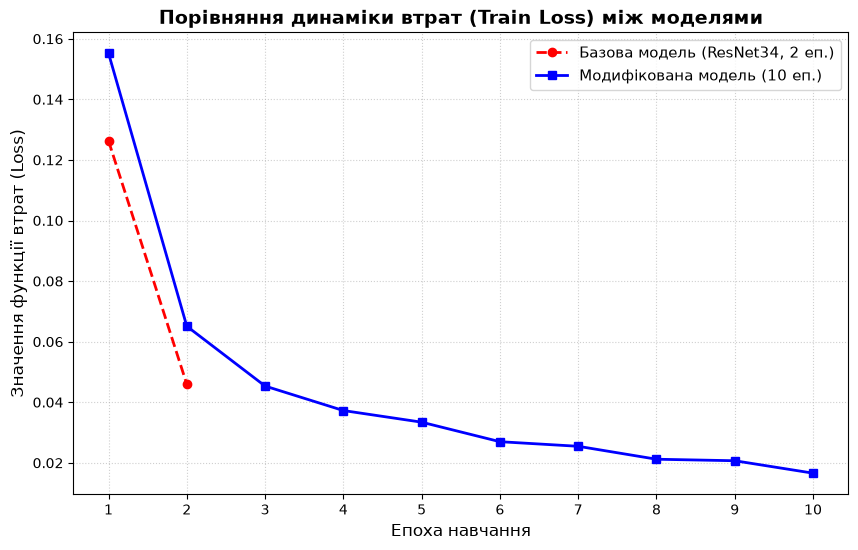

In [8]:
import matplotlib.pyplot as plt

# Налаштування розміру графіка
plt.figure(figsize=(10, 6))

epochs_base_range = range(1, len(train_losses_base) + 1)
epochs_modified_range = range(1, len(train_losses_modified) + 1)

# 1. Червона лінія для базової моделі (ResNet34) — побудується по своїх 2 епохах
plt.plot(epochs_base_range, train_losses_base, marker='o', linestyle='--', color='red', linewidth=2, label='Базова модель (ResNet34, 2 еп.)')

# 2. Синя лінія для модифікованої моделі (ModifiedCNN) — побудується по всіх 10 епохах
plt.plot(epochs_modified_range, train_losses_modified, marker='s', linestyle='-', color='blue', linewidth=2, label='Модифікована модель (10 еп.)')

# Оформлення графіка
plt.title('Порівняння динаміки втрат (Train Loss) між моделями', fontsize=14, fontweight='bold')
plt.xlabel('Епоха навчання', fontsize=12)
plt.ylabel('Значення функції втрат (Loss)', fontsize=12)

plt.xticks(range(1, max(len(train_losses_base), len(train_losses_modified)) + 1))  
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)

# Відображення
plt.show()

In [10]:
from IPython.display import display, Markdown

# Форматуємо змінні для гарного відображення (округлення до 4 знаків для Loss та 2 для Accuracy)
loss_b = f"{final_loss_base:.4f}" if isinstance(final_loss_base, float) else final_loss_base
loss_m = f"{final_loss_modified:.4f}" if isinstance(final_loss_modified, float) else final_loss_modified
acc_b = f"{accuracy_base:.2f}%" if isinstance(accuracy_base, float) else accuracy_base
acc_m = f"{accuracy_modified:.2f}%" if isinstance(accuracy_modified, float) else accuracy_modified

# Створюємо Markdown-таблицю за допомогою звичайного тексту
table_content = f"""

| Конфігурація | Accuracy | Loss | Примітка |
| :--- | :--- | :--- | :--- |
| **Базова (ResNet34)** | {acc_b} | {loss_b} | вихідна модель, довге навчання |
| **ModifiedCNN** | **{acc_m}** | **{loss_m}** | поліпшена стабільність, BatchNorm + Dropout |
"""

# Виводимо її на екран як гарну таблицю
display(Markdown(table_content))



| Конфігурація | Accuracy | Loss | Примітка |
| :--- | :--- | :--- | :--- |
| **Базова (ResNet34)** | 98.72% | 0.0459 | вихідна модель, довге навчання |
| **ModifiedCNN** | **99.11%** | **0.0166** | поліпшена стабільність, BatchNorm + Dropout |
